# CSE558 Data Science — Assignment 1

**Student:** Satyam Singh  
**Roll number / master seed:** `2024514`  
**Submission:** Individual (subject to instructor approval, as the assignment specifies pairs)

I used the default 10% KDD Cup 1999 dataset for both tasks. The notebook runs the full experiments, displays all plots inline, saves trial-level and summary tables, and generates a PDF report without repeating headers or footers. All randomized experiments use deterministic NumPy generators derived from the master seed.

**Execution:** In Google Colab, use **Runtime → Run all** and allow the dataset download on first use. The final cell regenerates `results/CSE558_2024514_Report.pdf`. I should download the executed notebook after it finishes, so its tables and figures remain embedded in the submitted `.ipynb`.


## Environment and reproducibility

I first ensure ReportLab is available for the PDF report. The scientific packages are normally available in Colab. I then fix the seed and create output directories. The timings below measure the runtime of this Colab session and can differ on another machine.


In [1]:
# Purpose: Install ReportLab only if the PDF dependency is missing.
import importlib.util, subprocess, sys
if importlib.util.find_spec("reportlab") is None:
    subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", "reportlab"])
print("ReportLab is installed and ready.")

ReportLab is installed and ready.


In [2]:
# Purpose: Import scientific packages, fix the master seed, and configure result folders.
import os, time, gc, json, warnings
from pathlib import Path
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from scipy import sparse
from sklearn.datasets import fetch_kddcup99
from sklearn.cluster import KMeans
from sklearn.preprocessing import OneHotEncoder
warnings.filterwarnings('ignore', category=FutureWarning)
SEED=2024514
OUT=Path('results'); FIG=OUT/'figures'; FIG.mkdir(parents=True,exist_ok=True)
np.random.seed(SEED)
def rng_for(*parts):
    return np.random.default_rng(np.random.SeedSequence([SEED,*map(int,parts)]))
def savefig(name):
    plt.tight_layout(); plt.savefig(FIG/name,dpi=180,bbox_inches='tight'); plt.show(); plt.close()
print('Seed:',SEED)

Seed: 2024514


## Dataset preparation
One-hot encode exactly `protocol_type`, `service`, and `flag`; convert the remaining features to float, remove constant columns, then min–max scale. The same resulting matrix is used in both questions.

### Dataset construction

I loaded the prescribed 10% KDD Cup 1999 data, encoded the three categorical features, removed constant columns, and normalized the remaining features. The same feature matrix is used throughout.

**Reading the output:** The tables show measured values; a ratio of 1 is the reference value, while values above 1 indicate increased cost or loss. Timings are machine-dependent.

In [3]:
# Purpose: I loaded the prescribed 10% KDD Cup 1999 data, encoded the three categorical features, removed constant columns, and normalized the remaining features.
t0=time.perf_counter()
kdd=fetch_kddcup99(subset=None,as_frame=True)
raw=kdd.data
text_cols=['protocol_type','service','flag']
num_cols=[c for c in raw.columns if c not in text_cols]
try: encoder=OneHotEncoder(handle_unknown='ignore',sparse_output=False,dtype=np.float32)
except TypeError: encoder=OneHotEncoder(handle_unknown='ignore',sparse=False,dtype=np.float32)
cat=encoder.fit_transform(raw[text_cols]); numeric=raw[num_cols].astype(np.float32).to_numpy()
D=np.concatenate([numeric,cat],axis=1).astype(np.float32)
del cat,numeric
mins=D.min(axis=0); maxs=D.max(axis=0)
keep=(maxs>mins)
D=D[:,keep]; D=(D-mins[keep])/(maxs[keep]-mins[keep]); D=np.ascontiguousarray(D,dtype=np.float32)
n,d=D.shape
y=np.asarray(kdd.target!=b'normal.',dtype=np.float64).reshape(-1)
assert n==len(y) and np.isfinite(D).all() and np.all(D>=0) and np.all(D<=1)
print('D shape:',D.shape,'removed constant columns:',int((~keep).sum()),'load time:',round(time.perf_counter()-t0,2))
(pd.DataFrame({'metric':['n','d','removed_constant_columns','seed'], 'value':[n,d,int((~keep).sum()),SEED]})).to_csv(OUT/'dataset_summary.csv',index=False)

D shape: (494021, 116) removed constant columns: 2 load time: 25.07


## Utilities
Cost is always calculated by assigning every original row to its **nearest** supplied centre, rather than using projected inertia. Squared distances use `float64` accumulation. CountSketch uses a sparse CSR accumulator, never a dense sketch matrix.

### Numerical helper functions

I defined explicit squared-distance, partition-cost, Gaussian projection, sparse CountSketch, and least-squares residual functions to make the calculations auditable.

**Reading the output:** The tables show measured values; a ratio of 1 is the reference value, while values above 1 indicate increased cost or loss. Timings are machine-dependent.

In [4]:
# Purpose: I defined explicit squared-distance, partition-cost, Gaussian projection, sparse CountSketch, and least-squares residual functions to make the calculations auditable.
def cost_nearest(X,centres,block=32768):
    centres=np.asarray(centres,dtype=np.float64)
    c2=np.sum(centres**2,axis=1)
    total=0.0
    for start in range(0,len(X),block):
        xb=np.asarray(X[start:start+block],dtype=np.float64)
        dist=np.sum(xb**2,axis=1)[:,None]+c2[None,:]-2*xb@centres.T
        total+=np.maximum(np.min(dist,axis=1),0).sum()
    return float(total)
def partition_cost(X,labels,k=15):
    counts=np.bincount(labels,minlength=k)
    sums=np.zeros((k,X.shape[1]),dtype=np.float64)
    np.add.at(sums,labels,X)
    total=np.sum(np.asarray(X,dtype=np.float64)**2)
    return float(total-np.sum((sums[counts>0]**2).sum(axis=1)/counts[counts>0]))
def lift_centres(X,labels,k=15):
    counts=np.bincount(labels,minlength=k)
    assert np.all(counts>0),'Unexpected empty cluster'
    sums=np.zeros((k,X.shape[1]),dtype=np.float64)
    np.add.at(sums,labels,X)
    return sums/counts[:,None]
def gaussian_projection(m,d,rng):
    return rng.normal(0,1/np.sqrt(m),size=(m,d)).astype(np.float32)
def countsketch(X,y,m,rng):
    h=rng.integers(0,m,size=len(X),dtype=np.int32)
    sign=rng.choice(np.array([-1.,1.],dtype=np.float64),size=len(X))
    # Sparse one-nonzero-per-column sketch; no dense S is ever created.
    S=sparse.csr_matrix((sign,(h,np.arange(len(X)))),shape=(m,len(X)))
    SX=np.asarray(S@X,dtype=np.float64)
    Sy=np.asarray(S@y,dtype=np.float64)
    return SX,Sy
def loss(X,y,a,block=50000):
    val=0.
    for start in range(0,len(X),block):
        z=np.asarray(X[start:start+block],dtype=np.float64)@a-y[start:start+block]
        val+=float(z@z)
    return val


## Question 1(a): Original-space k-means

### 1(a) — Original-space k-means baseline

I fitted 15 clusters in the original feature space and evaluated the sum of squared distances to the nearest centre. This provides the denominator for all projected clustering ratios.

**Reading the output:** The tables show measured values; a ratio of 1 is the reference value, while values above 1 indicate increased cost or loss. Timings are machine-dependent.

In [5]:
# Purpose: I fitted 15 clusters in the original feature space and evaluated the sum of squared distances to the nearest centre.
start=time.perf_counter()
km_D=KMeans(n_clusters=15,n_init=5,random_state=SEED).fit(D)
t_kmeans_D=time.perf_counter()-start
labels_D=km_D.labels_; B=km_D.cluster_centers_
base_cost=cost_nearest(D,B)
print('Original cost:',base_cost,'k-means wall time:',t_kmeans_D)
assert base_cost>0

# I compare the centre-assignment objective with the fixed-cluster objective for the fitted labels.
fixed_cost_D=partition_cost(D,labels_D)
print(f'Nearest-centre cost: {base_cost:.8f}; fixed-partition cost: {fixed_cost_D:.8f}; absolute difference: {abs(base_cost-fixed_cost_D):.6f}')
assert base_cost <= fixed_cost_D + 1e-3*max(1,fixed_cost_D)



Original cost: 54031.52439378831 k-means wall time: 33.307802365000015
Nearest-centre cost: 54031.52439379; fixed-partition cost: 54028.65252522; absolute difference: 2.871869


## Questions 1(b), 1(c), 1(d): Projected k-means, two lifting methods, and timings

### 1(b)–1(d) — Projected clustering, lifting, and speed

I tested five Gaussian projection dimensions, repeated each experiment five times, reconstructed centres by cluster means and pseudoinverse, and compared their original-space costs and execution times.

**Reading the output:** The tables show measured values; a ratio of 1 is the reference value, while values above 1 indicate increased cost or loss. Timings are machine-dependent.

**Interpretation:** In my five-run results, the mean cluster-mean-lift ratio falls from about 1.164 at m=5 to 1.016–1.028 at m=20–25, although it is not monotone (m=15 is slightly above m=10). Ratios below 1 can occur because k-means with `n_init=5` still finds only a local optimum.


Q1 5 1 hat 1.43585 pinv 79.49632 time 5.07
Q1 5 2 hat 1.05387 pinv 80.52267 time 4.28
Q1 5 3 hat 1.15812 pinv 78.76676 time 4.52
Q1 5 4 hat 1.12544 pinv 78.63941 time 4.37
Q1 5 5 hat 1.04676 pinv 78.79694 time 4.31
Q1 10 1 hat 1.00412 pinv 75.26248 time 4.44
Q1 10 2 hat 1.05372 pinv 75.45144 time 5.32
Q1 10 3 hat 1.14155 pinv 74.72186 time 4.55
Q1 10 4 hat 1.11804 pinv 78.94501 time 4.94
Q1 10 5 hat 1.06317 pinv 76.85945 time 4.48
Q1 15 1 hat 1.12871 pinv 63.8312 time 5.3
Q1 15 2 hat 1.08147 pinv 72.33272 time 5.28
Q1 15 3 hat 1.06562 pinv 75.24682 time 6.28
Q1 15 4 hat 1.03306 pinv 74.41958 time 5.54
Q1 15 5 hat 1.08135 pinv 72.52916 time 8.31
Q1 20 1 hat 0.99534 pinv 66.88047 time 7.1
Q1 20 2 hat 0.99614 pinv 68.49282 time 7.68
Q1 20 3 hat 1.00955 pinv 69.44198 time 7.55
Q1 20 4 hat 1.044 pinv 69.33689 time 8.65
Q1 20 5 hat 1.03507 pinv 70.01308 time 8.35
Q1 25 1 hat 1.07115 pinv 63.30997 time 8.55
Q1 25 2 hat 1.05059 pinv 69.23095 time 6.35
Q1 25 3 hat 1.02308 pinv 67.42383 time 6.3

,m,mean_hat,min_hat,max_hat,mean_pinv,min_pinv,max_pinv,mean_time_sec,mean_cost_hat,mean_cost_pinv
0,5,1.164009,1.046761,1.435846,79.244423,78.639413,80.522673,4.509954,62893.165367,4.281697e+06
1,10,1.076119,1.004116,1.141547,76.248049,74.721862,78.945013,4.745758,58144.353051,4.119798e+06
2,15,1.078039,1.033057,1.128708,71.671896,63.831205,75.246822,6.142103,58248.078180,3.872542e+06
3,20,1.016019,0.995343,1.044002,68.833049,66.880475,70.013085,7.865526,54897.063214,3.719155e+06
4,25,1.027905,0.976586,1.071152,67.314406,63.309970,69.477339,7.039629,55539.264523,3.637100e+06


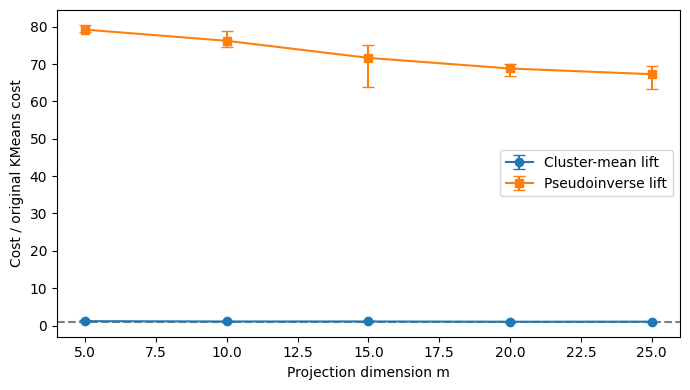

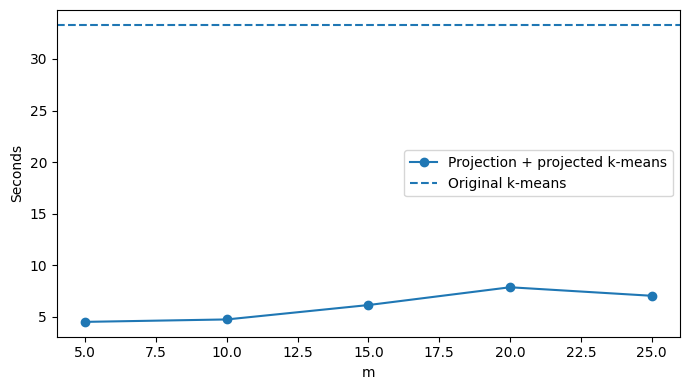

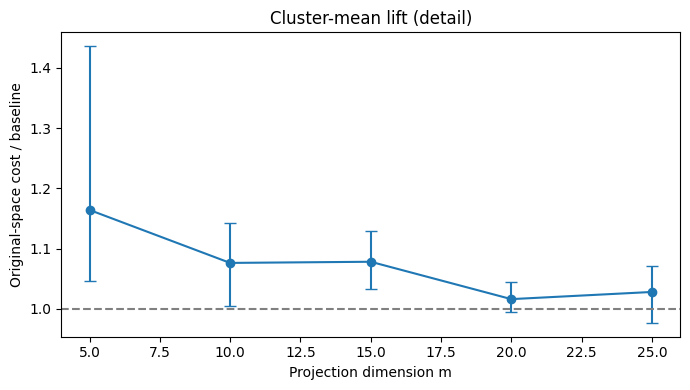

Interpretation: cluster-mean lifting stays much closer to the original-space baseline than pseudoinverse lifting.


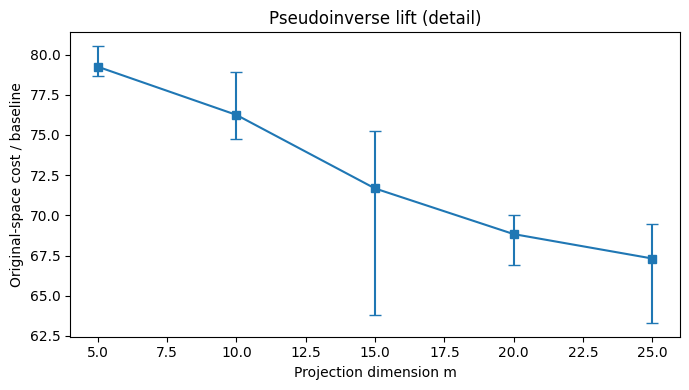

Five-run cost and runtime summaries are saved in results/q1_summary.csv; individual trials are in q1_all_runs.csv.


In [6]:
# Purpose: I tested five Gaussian projection dimensions, repeated each experiment five times, reconstructed centres by cluster means and pseudoinverse, and compared their original-space costs and execution times.
q1_records=[]
for m in [5,10,15,20,25]:
    for rep in range(5):
        rng=rng_for(1,m,rep)
        t0=time.perf_counter()
        A=gaussian_projection(m,d,rng)
        E=D@A.T
        km=KMeans(n_clusters=15,n_init=5,random_state=SEED+100*m+rep).fit(E)
        elapsed=time.perf_counter()-t0 # projection + KMeans only
        bhat=lift_centres(D,km.labels_)
        bplus=np.linalg.pinv(A.astype(np.float64))@km.cluster_centers_.astype(np.float64).T
        cost_hat=cost_nearest(D,bhat)
        cost_plus=cost_nearest(D,bplus.T)
        q1_records.append(dict(m=m,rep=rep+1,cost_hat=cost_hat,ratio_hat=cost_hat/base_cost,
                               cost_pinv=cost_plus,ratio_pinv=cost_plus/base_cost,time_sec=elapsed))
        print('Q1',m,rep+1,'hat',round(cost_hat/base_cost,5),'pinv',round(cost_plus/base_cost,5),'time',round(elapsed,2))
        del E,km,A,bhat,bplus
q1=pd.DataFrame(q1_records); q1.to_csv(OUT/'q1_all_runs.csv',index=False)
q1_summary=q1.groupby('m').agg(mean_hat=('ratio_hat','mean'),min_hat=('ratio_hat','min'),max_hat=('ratio_hat','max'),
    mean_pinv=('ratio_pinv','mean'),min_pinv=('ratio_pinv','min'),max_pinv=('ratio_pinv','max'),
    mean_time_sec=('time_sec','mean'),mean_cost_hat=('cost_hat','mean'),mean_cost_pinv=('cost_pinv','mean')).reset_index()
q1_summary.to_csv(OUT/'q1_summary.csv',index=False)
display(q1_summary)
plt.figure(figsize=(7,4));plt.errorbar(q1_summary.m,q1_summary.mean_hat,
 yerr=[q1_summary.mean_hat-q1_summary.min_hat,q1_summary.max_hat-q1_summary.mean_hat],fmt='o-',capsize=4,label='Cluster-mean lift')
plt.errorbar(q1_summary.m,q1_summary.mean_pinv,
 yerr=[q1_summary.mean_pinv-q1_summary.min_pinv,q1_summary.max_pinv-q1_summary.mean_pinv],fmt='s-',capsize=4,label='Pseudoinverse lift')
plt.axhline(1,ls='--',color='gray');plt.xlabel('Projection dimension m');plt.ylabel('Cost / original KMeans cost');plt.legend();savefig('q1_cost_ratios.png')
plt.figure(figsize=(7,4));plt.plot(q1_summary.m,q1_summary.mean_time_sec,'o-',label='Projection + projected k-means')
plt.axhline(t_kmeans_D,ls='--',label='Original k-means');plt.xlabel('m');plt.ylabel('Seconds');plt.legend();savefig('q1_times.png')
# Display both methods on separate scales so the near-optimal cluster-mean results remain visible.
plt.figure(figsize=(7,4));plt.errorbar(q1_summary.m,q1_summary.mean_hat,yerr=[q1_summary.mean_hat-q1_summary.min_hat,q1_summary.max_hat-q1_summary.mean_hat],fmt='o-',capsize=4);plt.axhline(1,ls='--',color='gray');plt.xlabel('Projection dimension m');plt.ylabel('Original-space cost / baseline');plt.title('Cluster-mean lift (detail)');savefig('q1_cluster_mean_detail.png')
print('Interpretation: cluster-mean lifting stays much closer to the original-space baseline than pseudoinverse lifting.')

# I also show the pseudoinverse results on their own axis to avoid compressing the cluster-mean curve.
plt.figure(figsize=(7,4))
plt.errorbar(q1_summary.m,q1_summary.mean_pinv,yerr=[q1_summary.mean_pinv-q1_summary.min_pinv,q1_summary.max_pinv-q1_summary.mean_pinv],fmt='s-',capsize=4)
plt.xlabel('Projection dimension m');plt.ylabel('Original-space cost / baseline')
plt.title('Pseudoinverse lift (detail)');savefig('q1_pseudoinverse_detail.png')
print('Five-run cost and runtime summaries are saved in results/q1_summary.csv; individual trials are in q1_all_runs.csv.')


## Question 1(e): Pairwise distortion versus fixed-partition cost distortion

### 1(e) — Pairwise distances and fixed-partition costs

I compared 10,000 fixed nonidentical data pairs with the cost of the original fixed partition under 20 independently drawn projections per dimension. The ratios need not be exactly one for a particular projection.

**Reading the output:** The tables show measured values; a ratio of 1 is the reference value, while values above 1 indicate increased cost or loss. Timings are machine-dependent.

**Interpretation:** Fixed-partition cost ratios have the smaller spread: their sample standard deviation falls from about 0.146 to 0.054, compared with 0.744 to 0.150 for pairwise ratios. Both generally shrink with m. For one fixed nonzero vector, a Gaussian projected squared-distance ratio follows χ²(m)/m across independent projections (standard deviation √(2/m)). Partition costs aggregate many residual vectors, reducing fluctuations, though the shared projection makes their contributions correlated.


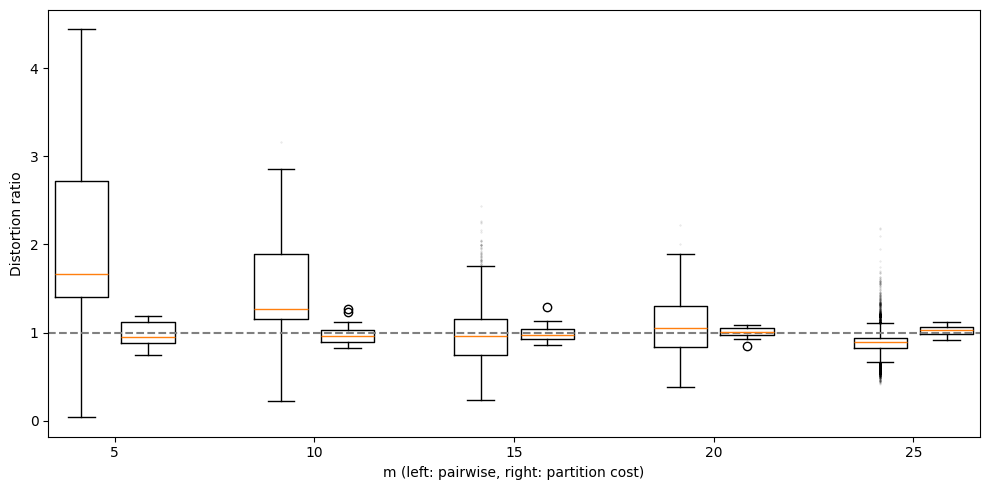

,m,pair_mean,pair_std,partition_mean,partition_std
0,5,1.895780,0.744332,0.969761,0.145829
1,10,1.376539,0.475549,0.977735,0.120777
2,15,0.952950,0.276936,0.996002,0.100053
3,20,1.056380,0.239176,1.000773,0.057072
4,25,0.880628,0.149849,1.022225,0.054241


Validation: for a fixed nonzero difference vector and an independent N(0,1/m) projection, the expected squared-distance ratio is 1.
A single projection is shared across all sampled pairs; the ratios are correlated, so a sample mean far from 1 is not proof of a bug.
m=5: pairwise mean=1.8958, median=1.6686, 5th–95th percentile=(0.7839,2.8852); partition mean=0.9698
m=10: pairwise mean=1.3765, median=1.2636, 5th–95th percentile=(0.5020,1.9758); partition mean=0.9777
m=15: pairwise mean=0.9529, median=0.9570, 5th–95th percentile=(0.5815,1.4153); partition mean=0.9960
m=20: pairwise mean=1.0564, median=1.0531, 5th–95th percentile=(0.7057,1.4021); partition mean=1.0008
m=25: pairwise mean=0.8806, median=0.8936, 5th–95th percentile=(0.5884,1.1184); partition mean=1.0222
Sanity checks passed: all pairwise and partition ratios are finite and nonnegative.


In [7]:
# Purpose: I compared 10,000 fixed nonidentical data pairs with the cost of the original fixed partition under 20 independently drawn projections per dimension.
rng=rng_for(1,999)
idx1=[];idx2=[]
while len(idx1)<10000:
    a=rng.integers(0,n,size=15000);b=rng.integers(0,n,size=15000)
    ok=(a!=b)&np.any(D[a]!=D[b],axis=1)
    take=min(10000-len(idx1),int(ok.sum()))
    idx1.extend(a[ok][:take]);idx2.extend(b[ok][:take])
idx1=np.asarray(idx1);idx2=np.asarray(idx2)
original_diff=np.asarray(D[idx1],dtype=np.float64)-np.asarray(D[idx2],dtype=np.float64)
original_sq=np.einsum('ij,ij->i',original_diff,original_diff)
base_partition=partition_cost(D,labels_D)
q1e_pair={};q1e_partition={}
for m in [5,10,15,20,25]:
    A=gaussian_projection(m,d,rng_for(1,1000,m))
    proj=original_diff@A.T
    q1e_pair[m]=np.sum(proj**2,axis=1)/original_sq
    values=[]
    for rep in range(20):
        A=gaussian_projection(m,d,rng_for(1,2000,m,rep))
        E=D@A.T
        values.append(partition_cost(E,labels_D)/base_partition)
    q1e_partition[m]=np.array(values)
np.savez_compressed(OUT/'q1e_distortions.npz',**{'pairs_'+str(m):v for m,v in q1e_pair.items()},
                    **{'partition_'+str(m):v for m,v in q1e_partition.items()})
fig,ax=plt.subplots(figsize=(10,5)); ms=[5,10,15,20,25]
ax.boxplot([q1e_pair[m] for m in ms],positions=np.arange(5)*3-0.5,widths=.8,showfliers=True,flierprops=dict(marker=".",markersize=1,alpha=0.12),patch_artist=False)
ax.boxplot([q1e_partition[m] for m in ms],positions=np.arange(5)*3+0.5,widths=.8,showfliers=True)
ax.set_xticks(np.arange(5)*3,ms);ax.set_xlabel('m (left: pairwise, right: partition cost)');ax.set_ylabel('Distortion ratio');ax.axhline(1,ls='--',color='gray');savefig('q1e_boxplots.png')
q1e_summary=pd.DataFrame([dict(m=m,pair_mean=q1e_pair[m].mean(),pair_std=q1e_pair[m].std(ddof=1),
 partition_mean=q1e_partition[m].mean(),partition_std=q1e_partition[m].std(ddof=1)) for m in ms])
q1e_summary.to_csv(OUT/'q1e_summary.csv',index=False);display(q1e_summary)
print('Validation: for a fixed nonzero difference vector and an independent N(0,1/m) projection, the expected squared-distance ratio is 1.')
print('A single projection is shared across all sampled pairs; the ratios are correlated, so a sample mean far from 1 is not proof of a bug.')
for m in [5,10,15,20,25]:
    vals=q1e_pair[m]
    print(f'm={m}: pairwise mean={vals.mean():.4f}, median={np.median(vals):.4f}, 5th–95th percentile=({np.percentile(vals,5):.4f},{np.percentile(vals,95):.4f}); partition mean={q1e_partition[m].mean():.4f}')

# I check that each projection's pairwise distortion is nonnegative and the fixed-partition ratios are positive.
assert all(np.isfinite(v).all() and (v>=0).all() for v in q1e_pair.values())
assert all(np.isfinite(v).all() and (v>0).all() for v in q1e_partition.values())
print('Sanity checks passed: all pairwise and partition ratios are finite and nonnegative.')


## Question 2(a): Full least squares

### 2(a) — Exact least-squares baseline

I solved the original least-squares problem without an intercept and measured the full residual sum of squares and solve time.

**Reading the output:** The tables show measured values; a ratio of 1 is the reference value, while values above 1 indicate increased cost or loss. Timings are machine-dependent.

In [8]:
# Purpose: I solved the original least-squares problem without an intercept and measured the full residual sum of squares and solve time.
start=time.perf_counter()
b=np.linalg.lstsq(np.asarray(D,dtype=np.float64),y,rcond=None)[0]
t_full=time.perf_counter()-start
base_loss=loss(D,y,b)
rank_D=int(np.linalg.matrix_rank(np.asarray(D,dtype=np.float64)))
v=np.asarray(D,dtype=np.float64)@b-y
print('rank(D)',rank_D,'loss',base_loss,'time',t_full)
assert base_loss>0

rank(D) 113 loss 2949.788814857174 time 6.963849884000069


## Questions 2(b), 2(c): CountSketch regression and timing

### 2(b)–2(c) — CountSketch regression and timing

I compared five independent sparse sketches at each target row count, measured their full-data losses relative to the optimum, and timed sketch construction plus solving.

**Reading the output:** The tables show measured values; a ratio of 1 is the reference value, while values above 1 indicate increased cost or loss. Timings are machine-dependent.

**Interpretation:** All five m=100 trials have poor full-data ratios, not just one outlier. Here m=100 is below the observed rank 113; `lstsq` finds a minimum-norm solution with nearly zero sketched residual, but the full-data fit is poor. This explains the observed peak without claiming that rank alone guarantees it. Sketch plus solve takes roughly 0.27–0.62 s versus 8.14 s for the full solve (about 13–30× faster); m=5000 is slower than most smaller sketches because its least-squares problem is larger.


Q2 50 1 ratio 2.98752 sketch loss 0.0 time 0.23
Q2 50 2 ratio 4.23274 sketch loss 0.0 time 0.23
Q2 50 3 ratio 3.52657 sketch loss 0.0 time 0.23
Q2 50 4 ratio 2.82287 sketch loss 0.0 time 0.23
Q2 50 5 ratio 5.10382 sketch loss 0.0 time 0.23
Q2 100 1 ratio 20.84544 sketch loss 0.0 time 0.26
Q2 100 2 ratio 9.70055 sketch loss 0.0 time 0.23
Q2 100 3 ratio 31.67455 sketch loss 0.0 time 0.24
Q2 100 4 ratio 5.91109 sketch loss 0.0 time 0.23
Q2 100 5 ratio 11.4962 sketch loss 0.0 time 0.24
Q2 200 1 ratio 2.43026 sketch loss 1022.8365 time 0.31
Q2 200 2 ratio 2.14935 sketch loss 1239.6594 time 0.24
Q2 200 3 ratio 2.14302 sketch loss 1106.8366 time 0.26
Q2 200 4 ratio 2.41396 sketch loss 1172.4678 time 0.23
Q2 200 5 ratio 2.40805 sketch loss 1185.7522 time 0.23
Q2 500 1 ratio 1.27707 sketch loss 2172.8796 time 0.29
Q2 500 2 ratio 1.29036 sketch loss 2403.7424 time 0.24
Q2 500 3 ratio 1.28426 sketch loss 2165.4496 time 0.24
Q2 500 4 ratio 1.36445 sketch loss 2456.7231 time 0.23
Q2 500 5 ratio 1.2

,m,mean_ratio,min_ratio,max_ratio,mean_loss,mean_sketched_loss,mean_time_sec
0,50,3.734706,2.822868,5.103822,11016.592683,2.818996e-24,0.230653
1,100,15.925564,5.911086,31.674547,46977.050948,1.878585e-23,0.238991
2,200,2.308927,2.143016,2.430257,6810.845820,1.145511e+03,0.253620
3,500,1.292770,1.247717,1.364445,3813.398600,2.265359e+03,0.332177
4,1000,1.131664,1.123450,1.141585,3338.169423,2.650041e+03,0.472259
5,2000,1.065664,1.055931,1.079827,3143.485088,2.833202e+03,0.264780
6,5000,1.026294,1.021106,1.034040,3027.351196,2.876124e+03,0.279282


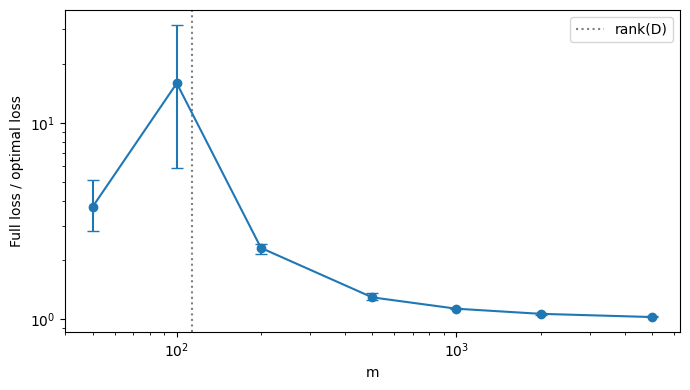

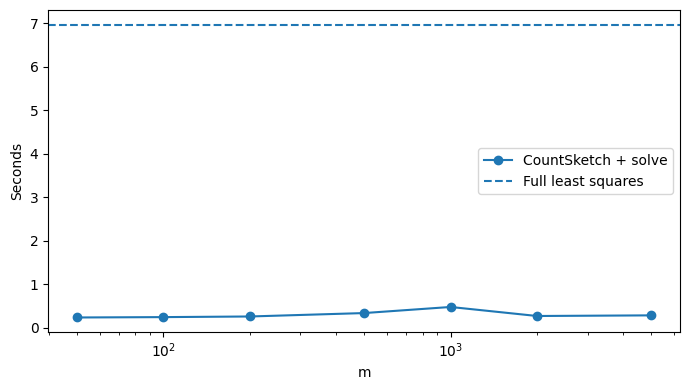

Interpretation: sketched training loss is not the same as original-data loss; a zero sketched loss can coexist with a large full-data loss.
Sanity check passed: all full-data sketch-loss ratios are at least 1 within tolerance.


In [9]:
# Purpose: I compared five independent sparse sketches at each target row count, measured their full-data losses relative to the optimum, and timed sketch construction plus solving.
q2_records=[]
for m in [50,100,200,500,1000,2000,5000]:
    for rep in range(5):
        t0=time.perf_counter()
        SD,Sy=countsketch(D,y,m,rng_for(2,m,rep))
        a=np.linalg.lstsq(SD,Sy,rcond=None)[0]
        elapsed=time.perf_counter()-t0
        full_l=loss(D,y,a);sk_l=float(np.sum((SD@a-Sy)**2))
        q2_records.append(dict(m=m,rep=rep+1,loss=full_l,ratio=full_l/base_loss,sketched_loss=sk_l,time_sec=elapsed))
        print('Q2',m,rep+1,'ratio',round(full_l/base_loss,5),'sketch loss',round(sk_l,4),'time',round(elapsed,2))
q2=pd.DataFrame(q2_records);q2.to_csv(OUT/'q2_all_runs.csv',index=False)
q2_summary=q2.groupby('m').agg(mean_ratio=('ratio','mean'),min_ratio=('ratio','min'),max_ratio=('ratio','max'),
 mean_loss=('loss','mean'),mean_sketched_loss=('sketched_loss','mean'),mean_time_sec=('time_sec','mean')).reset_index()
q2_summary.to_csv(OUT/'q2_summary.csv',index=False);display(q2_summary)
plt.figure(figsize=(7,4));plt.errorbar(q2_summary.m,q2_summary.mean_ratio,
 yerr=[q2_summary.mean_ratio-q2_summary.min_ratio,q2_summary.max_ratio-q2_summary.mean_ratio],fmt='o-',capsize=4)
plt.xscale('log');plt.yscale('log');plt.axvline(rank_D,ls=':',color='gray',label='rank(D)');plt.xlabel('m');plt.ylabel('Full loss / optimal loss');plt.legend();savefig('q2_ratio_loglog.png')
plt.figure(figsize=(7,4));plt.plot(q2_summary.m,q2_summary.mean_time_sec,'o-',label='CountSketch + solve')
plt.axhline(t_full,ls='--',label='Full least squares');plt.xscale('log');plt.xlabel('m');plt.ylabel('Seconds');plt.legend();savefig('q2_times.png')
print('Interpretation: sketched training loss is not the same as original-data loss; a zero sketched loss can coexist with a large full-data loss.')

# I verify the full-data least-squares objective never beats the computed optimum beyond numerical tolerance.
assert (q2['ratio'] >= 1-1e-5).all(), 'A sketched solution unexpectedly improves on the full least-squares optimum.'
print('Sanity check passed: all full-data sketch-loss ratios are at least 1 within tolerance.')


## Question 2(d): Residual norm preservation

### 2(d) — Norm preservation across 100 trials

I fixed the optimal residual vector and tested how its squared norm changes under 100 independent CountSketch matrices for each of three sketch sizes.

**Reading the output:** The tables show measured values; a ratio of 1 is the reference value, while values above 1 indicate increased cost or loss. Timings are machine-dependent.

**Interpretation:** The measured standard deviation drops from 0.198 to 0.065 to 0.019 as m increases from 50 to 500 to 5000, consistent with an approximately 1/√m trend. For CountSketch, the exact fixed-vector standard deviation is √[(2/m)(1 − Σvᵢ⁴/(Σvᵢ²)²)], at most √(2/m); the Gaussian χ²(m)/m formula is not generally exact for CountSketch.


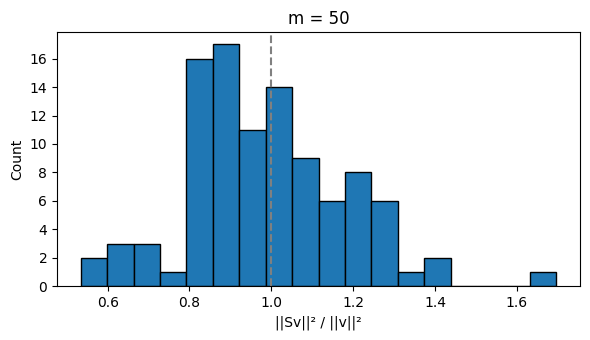

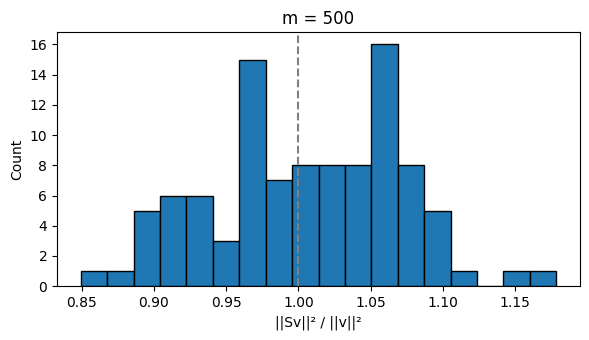

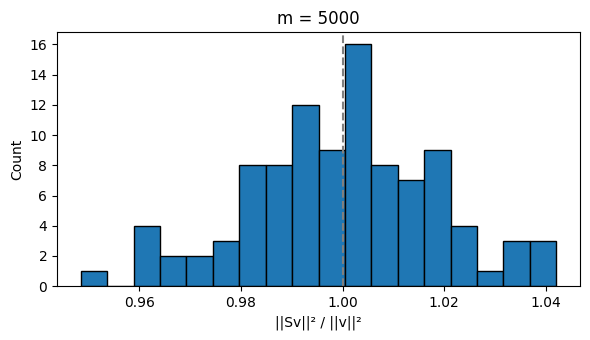

,m,mean,std
0,50,0.985794,0.198104
1,500,1.005637,0.064651
2,5000,0.999890,0.018767


Saved 300 individual norm-preservation ratios in results/q2d_all_trials.npz.


In [10]:
# Purpose: I fixed the optimal residual vector and tested how its squared norm changes under 100 independent CountSketch matrices for each of three sketch sizes.
q2d={};v2=float(v@v)
for m in [50,500,5000]:
    vals=[]
    for rep in range(100):
        rng=rng_for(2,3000,m,rep)
        h=rng.integers(0,m,size=n)
        signs=rng.choice([-1.,1.],size=n)
        Sv=np.bincount(h,weights=signs*v,minlength=m)
        vals.append(float(Sv@Sv/v2))
    q2d[m]=np.array(vals)
    plt.figure(figsize=(6,3.5));plt.hist(vals,bins=18,edgecolor='black');plt.axvline(1,ls='--',color='gray')
    plt.xlabel('||Sv||² / ||v||²');plt.ylabel('Count');plt.title('m = '+str(m));savefig('q2d_hist_'+str(m)+'.png')
q2d_summary=pd.DataFrame([dict(m=m,mean=q2d[m].mean(),std=q2d[m].std(ddof=1)) for m in q2d]);
q2d_summary.to_csv(OUT/'q2d_summary.csv',index=False);display(q2d_summary)
# I preserve all 100 residual-norm ratios per sketch size for reproducibility.
np.savez_compressed(OUT/'q2d_all_trials.npz',**{'m_'+str(mm):q2d[mm] for mm in q2d})
print('Saved 300 individual norm-preservation ratios in results/q2d_all_trials.npz.')


## Question 2(e): CountSketch versus dense Gaussian sketch on the same 50,000 rows
The dense Gaussian matrix is generated in chunks to bound memory, but its entries are independent Gaussian draws. The reported sketching time excludes the subsequent least-squares solve, as requested.

### 2(e) — Sparse versus dense sketching

I used the same 50,000 sampled rows and target sketch size for both methods, compared original-data loss ratios, and measured sketch construction and application time separately from regression solving.

**Reading the output:** The tables show measured values; a ratio of 1 is the reference value, while values above 1 indicate increased cost or loss. Timings are machine-dependent.

In [11]:
# Purpose: I used the same 50,000 sampled rows and target sketch size for both methods, compared original-data loss ratios, and measured sketch construction and application time separately from regression solving.
rng=rng_for(2,4000)
subset=rng.choice(n,size=50000,replace=False)
Ds=np.asarray(D[subset],dtype=np.float64);ys=y[subset]
bs=np.linalg.lstsq(Ds,ys,rcond=None)[0];subset_base_loss=loss(Ds,ys,bs)
q2e_records=[];m=500
for rep in range(5):
    for method in ['CountSketch','Dense Gaussian']:
        rr=rng_for(2,5000,rep,0 if method=='CountSketch' else 1)
        start=time.perf_counter()
        if method=='CountSketch':
            SD,Sy=countsketch(Ds,ys,m,rr)
        else:
            SD=np.zeros((m,d),dtype=np.float64);Sy=np.zeros(m,dtype=np.float64)
            for lo in range(0,50000,2000):
                hi=min(lo+2000,50000)
                G=rr.normal(0,1/np.sqrt(m),size=(m,hi-lo))
                SD+=G@Ds[lo:hi];Sy+=G@ys[lo:hi]
                del G
        sketch_time=time.perf_counter()-start
        a=np.linalg.lstsq(SD,Sy,rcond=None)[0]
        ratio=loss(Ds,ys,a)/subset_base_loss
        q2e_records.append(dict(method=method,rep=rep+1,sketch_time_sec=sketch_time,ratio=ratio))
        print(method,rep+1,'time',round(sketch_time,2),'ratio',round(ratio,5))
q2e=pd.DataFrame(q2e_records);q2e.to_csv(OUT/'q2e_all_runs.csv',index=False)
q2e_summary=q2e.groupby('method').agg(mean_sketch_time_sec=('sketch_time_sec','mean'),mean_ratio=('ratio','mean'),
 min_ratio=('ratio','min'),max_ratio=('ratio','max')).reset_index()
q2e_summary.to_csv(OUT/'q2e_summary.csv',index=False);display(q2e_summary)
print('Interpretation: both methods approximate the subset regression; CountSketch should usually have a much lower sketching cost.')


CountSketch 1 time 0.02 ratio 1.34976
Dense Gaussian 1 time 2.03 ratio 1.23918
CountSketch 2 time 0.02 ratio 1.30447
Dense Gaussian 2 time 1.77 ratio 1.2844
CountSketch 3 time 0.01 ratio 1.23959
Dense Gaussian 3 time 1.01 ratio 1.30645
CountSketch 4 time 0.02 ratio 1.24851
Dense Gaussian 4 time 0.99 ratio 1.31196
CountSketch 5 time 0.01 ratio 1.28692
Dense Gaussian 5 time 0.99 ratio 1.27526


,method,mean_sketch_time_sec,mean_ratio,min_ratio,max_ratio
0,CountSketch,0.015543,1.285848,1.239585,1.349756
1,Dense Gaussian,1.357778,1.283452,1.239183,1.311962


Interpretation: both methods approximate the subset regression; CountSketch should usually have a much lower sketching cost.


## Final PDF report generation — run only after all experiment cells

In [12]:
# Purpose: Build a self-contained PDF with all requested numerical results, plots, methods, interpretations, and trial-level appendices.
from reportlab.platypus import SimpleDocTemplate, Paragraph, Spacer, Table, TableStyle, Image, KeepTogether, PageBreak
from reportlab.lib import colors
from reportlab.lib.styles import getSampleStyleSheet, ParagraphStyle
from reportlab.lib.enums import TA_CENTER
from reportlab.lib.units import inch
from xml.sax.saxutils import escape
from PIL import Image as PILImage
styles=getSampleStyleSheet()
styles.add(ParagraphStyle(name='MainTitle2024',parent=styles['Title'],fontName='Helvetica-Bold',fontSize=17,leading=22,spaceAfter=13))
styles.add(ParagraphStyle(name='Heading2024',parent=styles['Heading2'],fontName='Helvetica-Bold',fontSize=11.4,leading=15,spaceBefore=14,spaceAfter=6,textColor=colors.HexColor('#233B53'),keepWithNext=True))
styles.add(ParagraphStyle(name='Body2024',parent=styles['BodyText'],fontSize=9,leading=13.6,spaceAfter=8))
styles.add(ParagraphStyle(name='Small2024',parent=styles['BodyText'],fontSize=8,leading=11.5,spaceAfter=6))
report=[]
def P(t):report.append(Paragraph(str(t),styles['Body2024']))
def H(t):report.append(Paragraph(escape(t),styles['Heading2024']))
def T(df,dec=4):
    cols=list(df.columns)
    vals=[[Paragraph(escape(str(x).replace('_',' ')),styles['Small2024']) for x in cols]]
    for row in df.itertuples(index=False,name=None):
        vals.append([f'{v:.{dec}f}' if isinstance(v,(float,np.floating)) else str(v) for v in row])
    available=511
    tbl=Table(vals,colWidths=[available/len(cols)]*len(cols),repeatRows=1,hAlign='LEFT')
    tbl.setStyle(TableStyle([('BACKGROUND',(0,0),(-1,0),colors.HexColor('#E9EEF3')),('GRID',(0,0),(-1,-1),.25,colors.HexColor('#B8C4CE')),('VALIGN',(0,0),(-1,-1),'MIDDLE'),('FONTSIZE',(0,1),(-1,-1),7),('LEFTPADDING',(0,0),(-1,-1),5),('RIGHTPADDING',(0,0),(-1,-1),5),('TOPPADDING',(0,0),(-1,-1),5),('BOTTOMPADDING',(0,0),(-1,-1),5)]))
    report.append(tbl);report.append(Spacer(1,10))
def Img(name,width=6.65):
    path=FIG/name
    with PILImage.open(path) as im:w,h=im.size
    report.append(Image(str(path),width=width*inch,height=width*inch*h/w))
    report.append(Spacer(1,8))
report.append(Paragraph('CSE558 Data Science — Assignment 1',styles['MainTitle2024']))
P('Satyam Singh | Roll number: 2024514 | Individual submission | Fixed master seed: 2024514')
P('I used the prescribed KDD Cup 1999 10% dataset for both experiments. Every numerical value in this report is generated from the notebook execution. I fixed the random generators for reproducibility; wall-clock timings are machine-dependent.')
H('Dataset and preprocessing')
P(f'I loaded {n:,} observations, one-hot encoded protocol_type, service and flag, converted the other attributes to numeric values, removed {int((~keep).sum())} constant encoded columns, and scaled every retained feature to [0,1]. The resulting matrix D has shape ({n:,}, {d}). I used the same matrix in both questions.')
H('1(a) — Original-space k-means baseline')
P(f'I fitted KMeans with k=15, n_init=5, and a fixed random_state. I computed cost(D,B) by assigning every row to its nearest fitted centre and summing squared Euclidean distances. The baseline cost is {base_cost:.6f}; the measured clustering time is {t_kmeans_D:.4f} seconds. This cost is a local-optimization result, not a certified global minimum.')
H('1(b) and 1(c) — Projected clustering and reconstruction')
P('I sampled each Gaussian projection A with independent N(0,1/m) entries, formed E = D A-transpose, and ran k-means in the projected space. I repeated this five times at every m in {5,10,15,20,25}. I reconstructed the original-space centres by (i) averaging the original rows assigned to each projected cluster and (ii) applying the pseudoinverse A-plus to the projected centres. I evaluated both reconstructed centre sets against all original rows using the nearest-centre objective.')
P('For a fixed partition, the original-space cluster means minimize its sum of squared distances. A pseudoinverse lift instead recovers a minimum-norm preimage of each projected centre and need not reproduce the original cluster mean. Therefore I prefer the cluster-mean lift for the final clustering.')
T(q1_summary[['m','mean_cost_hat','mean_hat','min_hat','max_hat','mean_pinv','min_pinv','max_pinv']])
P('The columns mean_hat, min_hat and max_hat summarize the five original-space cost ratios for cluster-mean lifting; mean_pinv, min_pinv and max_pinv are the corresponding pseudoinverse ratios. The mean_cost_hat column is the mean original-space cost, not a ratio.')
Img('q1_cost_ratios.png');Img('q1_cluster_mean_detail.png');Img('q1_pseudoinverse_detail.png')
P('The shared-scale plot makes the large pseudoinverse ratios evident; the two detailed plots show each method without compressing the other. In my five-run results, the mean cluster-mean-lift ratio decreases from 1.164 at m=5 to 1.016 at m=20 and 1.028 at m=25. The trend is not strictly monotone: m=15 (1.078) is slightly worse than m=10 (1.076). Ratios below 1 are possible because the original k-means baseline, even with n_init=5, is a local optimum rather than a guaranteed global minimum.')
H('1(d) — Projection and k-means timing')
P('I timed only Gaussian projection construction, matrix projection and projected-space k-means, excluding centre lifting and original-space cost evaluation. The table averages the five runs for each m and the dashed reference line shows the original-space k-means time.')
T(q1_summary[['m','mean_time_sec']]);Img('q1_times.png')
H('1(e) — Pairwise distance versus fixed-partition distortion')
P('I sampled 10,000 nonidentical row pairs once and reused them across all m. For each m I used one Gaussian matrix to calculate the 10,000 ratios of projected to original squared pairwise distances. Separately, I held the original-space cluster labels fixed and used 20 fresh Gaussian projections to calculate the projected/original fixed-partition cost ratios. Both distributions appear side by side for each m.')
P('For any fixed nonzero difference vector x, E[||Ax|| squared] = ||x|| squared, because the entries of A have variance 1/m. The expectation of each ratio is therefore 1. However, all 10,000 pairs at a given m share one projection, so their ratios are correlated and their sample mean can differ substantially from 1. Fixed-partition costs average over many vectors and usually fluctuate less.')
T(q1e_summary);Img('q1e_boxplots.png')
P('The fixed-partition cost ratios (ii) have the smaller spread at every tested dimension: their standard deviations decrease from about 0.146 to 0.054, versus 0.744 to 0.150 for the pairwise ratios (i), as m grows from 5 to 25. Both spreads generally shrink as m increases. For each fixed nonzero pair, the Gaussian squared-distance ratio has distribution chi-square(m)/m over independent projections, with standard deviation sqrt(2/m). The partition-cost ratio combines contributions from many original-space within-cluster residual vectors, which tends to smooth fluctuations; these contributions share the same projection, so they are correlated rather than independent.')
H('2(a) — Full least-squares reference')
P(f'I encoded attacks as y=1 and normal connections as y=0, then solved min_a ||Da-y|| squared with numpy.linalg.lstsq and no intercept. The computed rank is {rank_D}, the reference loss is {base_loss:.8f}, and the measured solve time is {t_full:.4f} seconds. This reference loss is the denominator of every full-data approximation ratio.')
H('2(b) — CountSketch least squares')
P('I generated one independent bucket index and random sign per original row, represented CountSketch sparsely, and formed SD and Sy without materializing a dense m-by-n matrix. For each m in {50,100,200,500,1000,2000,5000}, I fitted five independently sketched least-squares models. I report the original-data loss, its ratio to the full optimum, and the objective value on the sketched system.')
T(q2_summary[['m','mean_loss','mean_ratio','min_ratio','max_ratio','mean_sketched_loss']]);Img('q2_ratio_loglog.png')
P('When m is below rank(D), SD cannot have full column rank; its sketched objective can be nearly zero even if the fitted coefficients have poor full-data loss. When m is sufficiently large, the sketch typically preserves the regression geometry better and the full-loss ratio approaches 1. All five m=100 runs have poor original-data loss ratios (5.91 to 31.67), producing the observed peak in the five-run mean. Since m=100 is below rank(D)=113, the sketched system is underdetermined in its effective feature space; numpy.linalg.lstsq returns a minimum-norm solution with essentially zero sketched residual, but this need not fit the original data well. Proximity to the rank threshold helps explain instability, although it does not by itself guarantee this peak. At or above rank(D), a nonzero sketched loss is common, but not guaranteed by the rank threshold alone.')
H('2(c) — Sketch construction plus least-squares timing')
P('For each trial I timed drawing the CountSketch, constructing SD and Sy, and solving the sketched least-squares problem. I excluded the separate full-data loss evaluation. The dashed line gives the reference time for solving the full problem.')
T(q2_summary[['m','mean_time_sec']]);Img('q2_times.png')
P(f'Across the tested sketch sizes, sketch construction plus solving takes about {q2_summary.mean_time_sec.min():.2f} to {q2_summary.mean_time_sec.max():.2f} seconds, compared with {t_full:.2f} seconds for full least squares. This is approximately {t_full/q2_summary.mean_time_sec.max():.0f} to {t_full/q2_summary.mean_time_sec.min():.0f} times faster. At m=5000 the larger sketched least-squares system raises the solve time relative to most smaller sketches.')
H('2(d) — Residual-norm preservation')
P('I fixed v=Db-y from the full solution. For each m in {50,500,5000}, I drew 100 independent CountSketch mappings and computed ||Sv|| squared / ||v|| squared. I report sample means and sample standard deviations (ddof=1) and show the full empirical distributions below.')
T(q2d_summary)
for mm in [50,500,5000]:Img('q2d_hist_'+str(mm)+'.png',width=5.6)
P('Each fixed residual has expected squared-norm ratio 1 because cross terms cancel under independent random signs. Increasing m reduces bucket collisions and typically reduces variance. In my results the standard deviations decrease from about 0.198 (m=50) to 0.065 (m=500) to 0.019 (m=5000), approximately a factor of three for each tenfold increase in m. For independent CountSketch bucket assignments and signs, the exact standard deviation of this fixed-vector squared-norm ratio is sqrt((2/m) * (1 - sum(v_i^4)/(sum(v_i^2)^2))), which is at most sqrt(2/m). Thus the observed approximate 1/sqrt(m) trend agrees with the CountSketch variance calculation; sqrt(2/m) is not universally an exact CountSketch standard deviation.')
H('2(e) — Sparse CountSketch versus dense Gaussian sketch')
P(f'I sampled 50,000 rows without replacement once and used exactly that subset for both methods in all five repetitions. I solved a fresh subset least-squares reference problem with loss {subset_base_loss:.8f}. At m=500, I generated five independent sketches for each method, solved their sketched problems, and evaluated every result against the full 50,000-row subset. I measured only sketch generation and application time, excluding the least-squares solve, as requested.')
T(q2e_summary)
P('I generated the dense Gaussian sketch in independent blocks to limit peak memory, while retaining the required N(0,1/m) distribution. CountSketch generally has lower sketching cost because each input row contributes to only one bucket. On the full dataset I would choose CountSketch for its lower memory requirements and faster sketch application, while checking that its measured approximation quality is acceptable.')
H('Reproducibility, checks and sources')
P('I used master seed 2024514 with deterministic child generators for each experiment, n_init=5 for all KMeans runs, and numpy.linalg.lstsq for every least-squares fit. The notebook saves trial-level CSVs, summary CSVs, distortion and residual-ratio NPZ files, and the figures used here. The notebook also checks nonnegative distortion ratios and that sketched full-data regression losses do not beat the reference optimum beyond numerical tolerance.')
P('Dataset/API reference: https://scikit-learn.org/stable/modules/generated/sklearn.datasets.fetch_kddcup99.html . The implementation uses NumPy, SciPy, pandas, scikit-learn, matplotlib, and ReportLab. I have not listed any other groups as collaborators.')
H('Appendix A — All five projected-clustering runs')
T(q1[['m','rep','cost_hat','ratio_hat','cost_pinv','ratio_pinv','time_sec']],dec=3)
H('Appendix B — All five CountSketch regression runs')
T(q2[['m','rep','loss','ratio','sketched_loss','time_sec']],dec=3)
H('Appendix C — All dense-versus-sparse sketch runs')
T(q2e[['method','rep','sketch_time_sec','ratio']],dec=4)
pdf=OUT/'CSE558_2024514_Report.pdf'
SimpleDocTemplate(str(pdf),pagesize=(595.28,841.89),leftMargin=42,rightMargin=42,topMargin=42,bottomMargin=42,title='CSE558 Assignment 1 — 2024514').build(report)
print('Generated final report:',pdf,'(',pdf.stat().st_size,'bytes )')
print('Download the regenerated PDF and the executed notebook after Run all completes.')


Generated final report: results/CSE558_2024514_Report.pdf ( 424247 bytes )
Download the regenerated PDF and the executed notebook after Run all completes.
